# Homework 7: Unsupervised Learning, Bagging & Boosting

In [6]:
# ============================================================
# HW7: Campus Store Purchases
# Unsupervised Learning + Bagging + Boosting
# ============================================================

import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, learning_curve, validation_curve
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, classification_report
)
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from scipy.cluster.hierarchy import dendrogram, linkage

try:
    from xgboost import XGBClassifier
    xgb_available = True
except:
    xgb_available = False
    print("XGBoost not installed. Skipping XGBoost.")

RANDOM_STATE = 42
TEST_SIZE = 0.2

## 1. Data Loading & Preprocessing

In [7]:

# ============================================================
# 1. Load Dataset
# ============================================================

df = pd.read_csv("campus_store_purchases_hw7.csv")

print(df.head())
print(df.info())
print(df["Category"].value_counts())



  SessionID  TimeOfDay                                      ItemsBought  \
0     S1000    Morning                                   Mouse>Bookmark   
1     S1001  Afternoon                       Controller>Keyboard>Coffee   
2     S1002    Morning                                      Pen>Planner   
3     S1003    Morning  Sticky_Notes>Highlighter>Index_Cards>Pencil_Set   
4     S1004    Evening                                      Thermometer   

      Category  
0  Electronics  
1       Gaming  
2        Books  
3      Library  
4      Medical  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   SessionID    300 non-null    object
 1   TimeOfDay    300 non-null    object
 2   ItemsBought  300 non-null    object
 3   Category     300 non-null    object
dtypes: object(4)
memory usage: 9.5+ KB
None
Category
Gaming         41
Electronics    38
Library

In [8]:
# ============================================================
# 2. Feature Engineering
# ============================================================

# Multi-hot encode ItemsBought
items_split = df["ItemsBought"].str.split(">")
all_items = sorted(set(item for sublist in items_split for item in sublist))

item_features = pd.DataFrame(0, index=df.index, columns=all_items)

for i, items in enumerate(items_split):
    for item in items:
        item_features.loc[i, item] = 1

# Encode TimeOfDay
time_mapping = {
    "Morning": 0,
    "Afternoon": 1,
    "Evening": 2,
    "Night": 3
}

time_feature = df["TimeOfDay"].map(time_mapping).to_frame("TimeOfDay_Encoded")

# Final feature matrix
X = pd.concat([time_feature, item_features], axis=1)

# Target only for evaluation/supervised learning
y_true = df["Category"].values

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

feature_names = X.columns

print("Feature matrix shape:", X.shape)
print("Features:", list(feature_names))

Feature matrix shape: (300, 63)
Features: ['TimeOfDay_Encoded', 'Adapter', 'Antiseptic', 'Bandage', 'Bookmark', 'Brush', 'Calculator', 'Canvas', 'Cap', 'Charcoal', 'Charger', 'Coffee', 'Controller', 'Dictionary', 'Energy_Drink', 'Eraser', 'Folder', 'Game_Card', 'Gloves', 'Headphones', 'Highlighter', 'Hoodie', 'Index_Cards', 'Jacket', 'Juice', 'Keyboard', 'Lanyard', 'Library_Card', 'Mask', 'Mouse', 'Mousepad', 'Muffin', 'Notebook', 'Novel', 'ORS', 'Paint', 'Palette', 'Paracetamol', 'Pen', 'Pencil_Set', 'Planner', 'Powerbank', 'Protein_Bar', 'Ruler', 'Sandwich', 'Shorts', 'Sketchbook', 'Snack', 'Socks', 'Sports_Tape', 'Stapler', 'Sticky_Notes', 'T_Shirt', 'Tape', 'Tea', 'Textbook', 'Thermometer', 'Towel', 'USB', 'Vitamins', 'Water', 'Water_Bottle', 'Whistle']


## 2a. PCA

Components needed for >=85% variance: 43


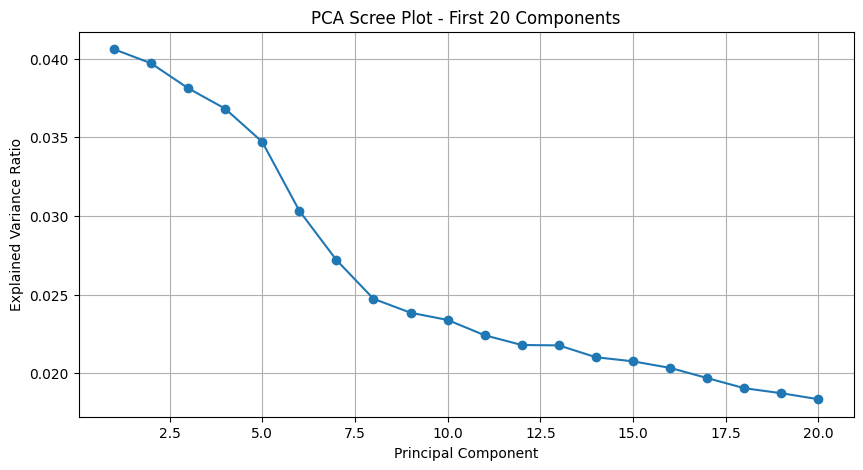

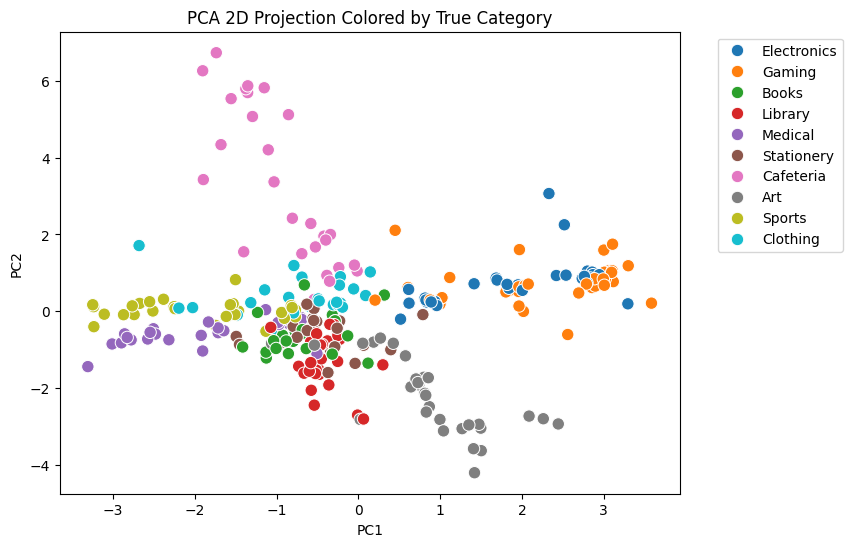

Top 3 features on PC1:
Keyboard    0.292524
Charger     0.292477
USB         0.265814
Name: PC1, dtype: float64

Top 3 features on PC2:
Snack       0.354415
Muffin      0.351590
Sandwich    0.277494
Name: PC2, dtype: float64


In [9]:
# ============================================================
# 3. PCA
# ============================================================

pca = PCA(random_state=RANDOM_STATE)
X_pca_full = pca.fit_transform(X_scaled)

explained_var = pca.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

n_components_85 = np.argmax(cum_var >= 0.85) + 1
print("Components needed for >=85% variance:", n_components_85)

plt.figure(figsize=(10, 5))
plt.plot(range(1, min(21, len(explained_var)+1)), explained_var[:20], marker="o")
plt.title("PCA Scree Plot - First 20 Components")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.grid(True)
plt.show()

# PCA 2D
pca_2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2 = pca_2.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca_2[:, 0], y=X_pca_2[:, 1], hue=y_true, s=80)
plt.title("PCA 2D Projection Colored by True Category")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

# Top 3 features on PC1 and PC2
loadings = pd.DataFrame(
    pca_2.components_.T,
    columns=["PC1", "PC2"],
    index=feature_names
)

print("Top 3 features on PC1:")
print(loadings["PC1"].abs().sort_values(ascending=False).head(3))

print("\nTop 3 features on PC2:")
print(loadings["PC2"].abs().sort_values(ascending=False).head(3))

## 2b. t-SNE

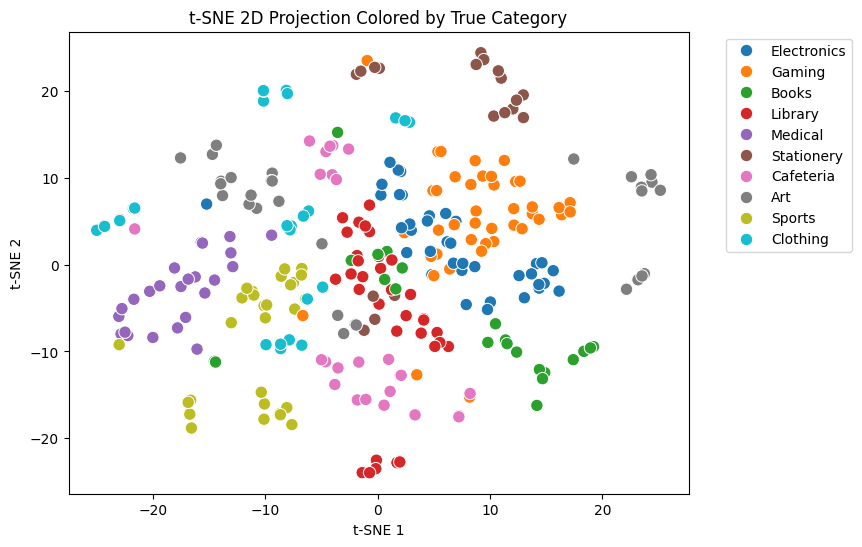

In [10]:
# ============================================================
# 4. t-SNE
# ============================================================

perplexity_value = 30

if len(df) <= 30:
    perplexity_value = max(2, len(df)//3)
    print("Small dataset detected. Using t-SNE perplexity:", perplexity_value)

tsne = TSNE(
    n_components=2,
    perplexity=perplexity_value,
    random_state=RANDOM_STATE,
    init="random",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_true, s=80)
plt.title("t-SNE 2D Projection Colored by True Category")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()


### PCA vs t-SNE Comparison

## 3. Clustering

In [11]:
# ============================================================
# Helper Function: Cluster Purity
# ============================================================

def cluster_purity(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    total = 0

    for cluster in np.unique(y_pred):
        if cluster == -1:
            continue

        indices = np.where(y_pred == cluster)[0]
        true_labels = y_true[indices]

        if len(true_labels) > 0:
            most_common = pd.Series(true_labels).value_counts().max()
            total += most_common

    return total / len(y_true)

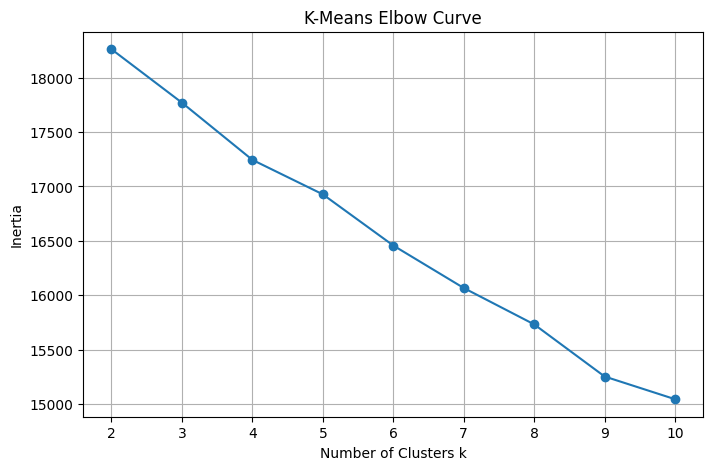

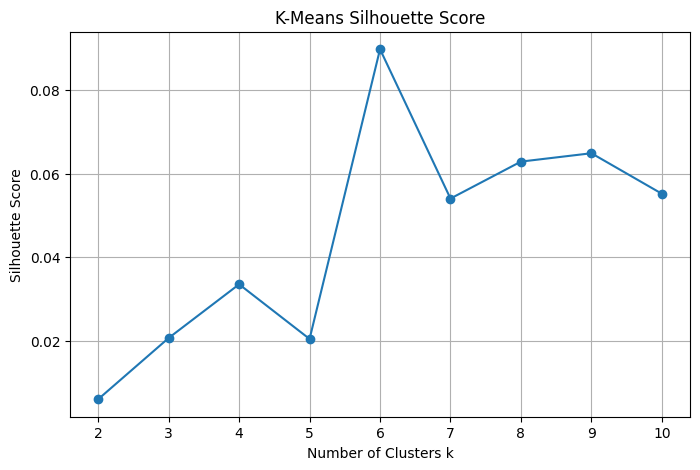

Best k based on highest silhouette score: 6


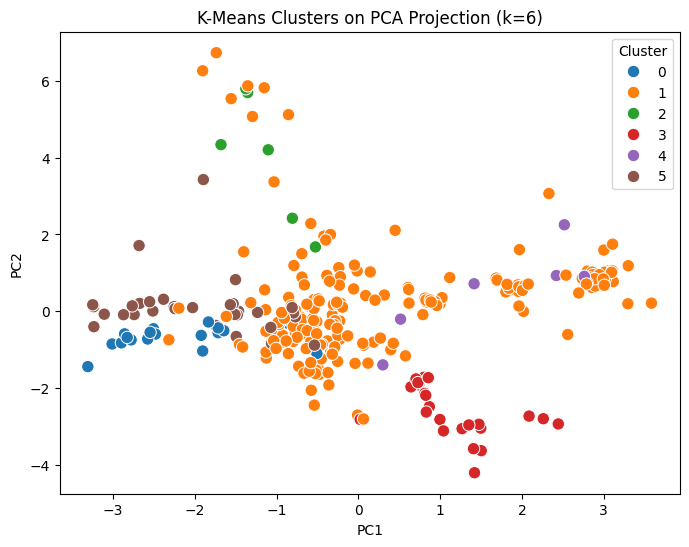

# K-Means
k = 6
silhouette_score = 0.0898
cluster_purity = 0.3967


In [12]:
# ============================================================
# 5. K-Means Clustering
# ============================================================

k_range = range(2, 11)

inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)

    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertias, marker="o")
plt.title("K-Means Elbow Curve")
plt.xlabel("Number of Clusters k")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(list(k_range), silhouettes, marker="o")
plt.title("K-Means Silhouette Score")
plt.xlabel("Number of Clusters k")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

best_k = list(k_range)[np.argmax(silhouettes)]
print("Best k based on highest silhouette score:", best_k)

kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
kmeans_purity = cluster_purity(y_true, kmeans_labels)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca_2[:, 0], y=X_pca_2[:, 1], hue=kmeans_labels, palette="tab10", s=80)
plt.title(f"K-Means Clusters on PCA Projection (k={best_k})")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.show()

print("# K-Means")
print("k =", best_k)
print("silhouette_score =", round(kmeans_silhouette, 4))
print("cluster_purity =", round(kmeans_purity, 4))

### K-Means Best-k Justification

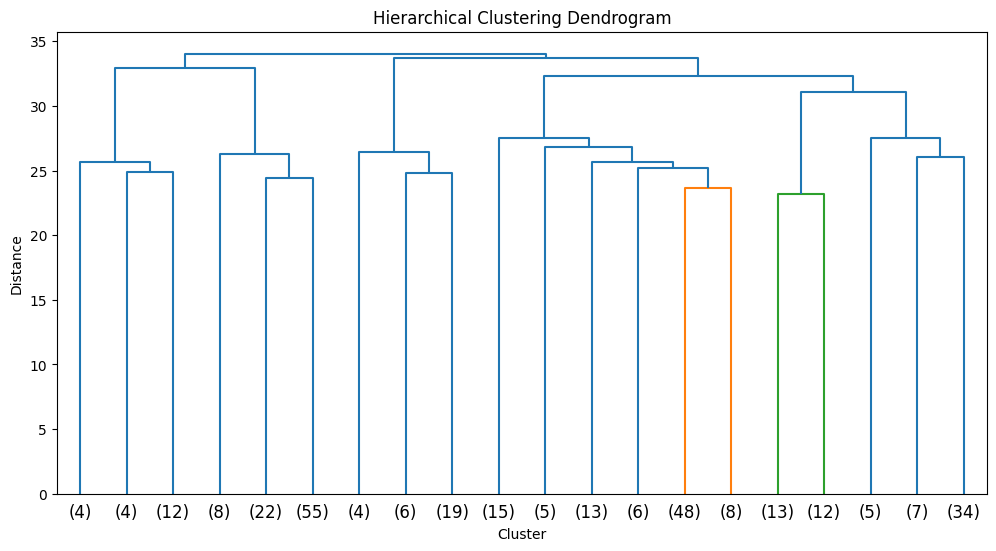

# Hierarchical Clustering
linkage = ward
k = 6
silhouette_score = 0.0373
cluster_purity = 0.5633


In [13]:

# ============================================================
# 6. Hierarchical Agglomerative Clustering
# ============================================================

agg = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
agg_labels = agg.fit_predict(X_scaled)

agg_silhouette = silhouette_score(X_scaled, agg_labels)
agg_purity = cluster_purity(y_true, agg_labels)

linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(linked, truncate_mode="lastp", p=20)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster")
plt.ylabel("Distance")
plt.show()

print("# Hierarchical Clustering")
print("linkage = ward")
print("k =", best_k)
print("silhouette_score =", round(agg_silhouette, 4))
print("cluster_purity =", round(agg_purity, 4))


In [14]:
# ============================================================
# 7. DBSCAN
# ============================================================

eps_range = [0.3, 0.5, 0.8, 1.0, 1.5]
min_samples_range = [3, 5, 10]

dbscan_results = []

for eps in eps_range:
    for min_samples in min_samples_range:
        db = DBSCAN(eps=eps, min_samples=min_samples)
        labels = db.fit_predict(X_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_pct = np.mean(labels == -1)

        if n_clusters > 1 and noise_pct < 0.5:
            sil = silhouette_score(X_scaled, labels)
            purity = cluster_purity(y_true, labels)

            dbscan_results.append({
                "eps": eps,
                "min_samples": min_samples,
                "n_clusters": n_clusters,
                "noise_pct": noise_pct,
                "silhouette": sil,
                "purity": purity,
                "labels": labels
            })

if len(dbscan_results) > 0:
    dbscan_df = pd.DataFrame(dbscan_results).drop(columns=["labels"])
    print(dbscan_df)

    best_dbscan = max(dbscan_results, key=lambda x: x["silhouette"])
    dbscan_labels = best_dbscan["labels"]
    dbscan_silhouette = best_dbscan["silhouette"]
    dbscan_purity = best_dbscan["purity"]
    dbscan_clusters = best_dbscan["n_clusters"]

    print("# DBSCAN")
    print("eps =", best_dbscan["eps"])
    print("min_samples =", best_dbscan["min_samples"])
    print("n_clusters =", best_dbscan["n_clusters"])
    print("noise_pct =", round(best_dbscan["noise_pct"], 4))
    print("silhouette =", round(dbscan_silhouette, 4))
    print("cluster_purity =", round(dbscan_purity, 4))
else:
    print("No valid DBSCAN configuration found.")
    dbscan_silhouette = np.nan
    dbscan_purity = np.nan
    dbscan_clusters = np.nan
    best_dbscan = {
        "eps": None,
        "min_samples": None
    }


No valid DBSCAN configuration found.


## 4. Cluster Evaluation Summary

In [15]:
# ============================================================
# 8. Clustering Summary Table
# ============================================================

cluster_summary = pd.DataFrame({
    "Method": ["K-Means", "Agglomerative", "DBSCAN"],
    "Best Params": [
        f"k={best_k}",
        f"ward, k={best_k}",
        f"eps={best_dbscan['eps']}, min_samples={best_dbscan['min_samples']}"
    ],
    "# Clusters": [
        best_k,
        best_k,
        dbscan_clusters
    ],
    "Silhouette Score": [
        kmeans_silhouette,
        agg_silhouette,
        dbscan_silhouette
    ],
    "Cluster Purity": [
        kmeans_purity,
        agg_purity,
        dbscan_purity
    ]
})

display(cluster_summary)

,Method,Best Params,# Clusters,Silhouette Score,Cluster Purity
0,K-Means,k=6,6.0,0.089761,0.396667
1,Agglomerative,"ward, k=6",6.0,0.037339,0.563333
2,DBSCAN,"eps=None, min_samples=None",NaN,NaN,NaN


### Cluster Evaluation Discussion

## 5. Bagging — Random Forest

In [16]:
# ============================================================
# 9. Supervised Train-Test Split
# ============================================================

le = LabelEncoder()
y_encoded = le.fit_transform(y_true)

if len(df) < 50:
    TEST_SIZE = 0.3
    print("Small sample detected. Results are for code testing only.")

class_counts = pd.Series(y_encoded).value_counts()

if class_counts.min() >= 2:
    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled,
        y_encoded,
        test_size=TEST_SIZE,
        stratify=y_encoded,
        random_state=RANDOM_STATE
    )
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled,
        y_encoded,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE
    )

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Target classes:", list(le.classes_))

# CV fallback
train_class_counts = pd.Series(y_train).value_counts()
min_class_count = train_class_counts.min()
cv_folds = min(5, min_class_count)

print("Training class counts:")
print(train_class_counts)
print("Using cv =", cv_folds)

Train shape: (240, 63)
Test shape: (60, 63)
Target classes: ['Art', 'Books', 'Cafeteria', 'Clothing', 'Electronics', 'Gaming', 'Library', 'Medical', 'Sports', 'Stationery']
Training class counts:
5    33
4    30
6    27
0    26
8    25
2    22
7    21
3    20
1    18
9    18
Name: count, dtype: int64
Using cv = 5


# Random Forest
best_params = {'max_depth': 10, 'max_features': 'log2', 'n_estimators': 200}

Test Accuracy: 0.8000
Macro Precision: 0.8388
Macro Recall: 0.8107
Macro F1: 0.8044
Training Time (s): 29.5326


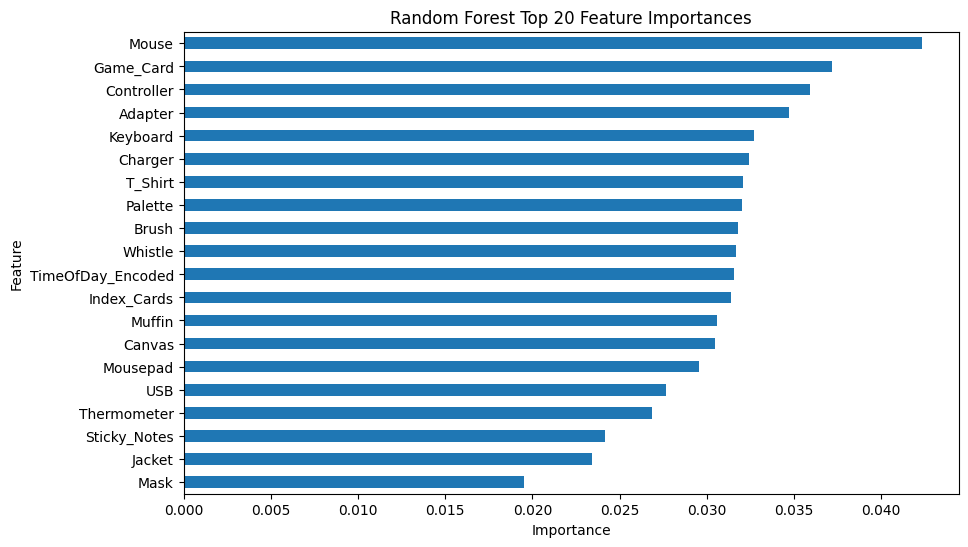

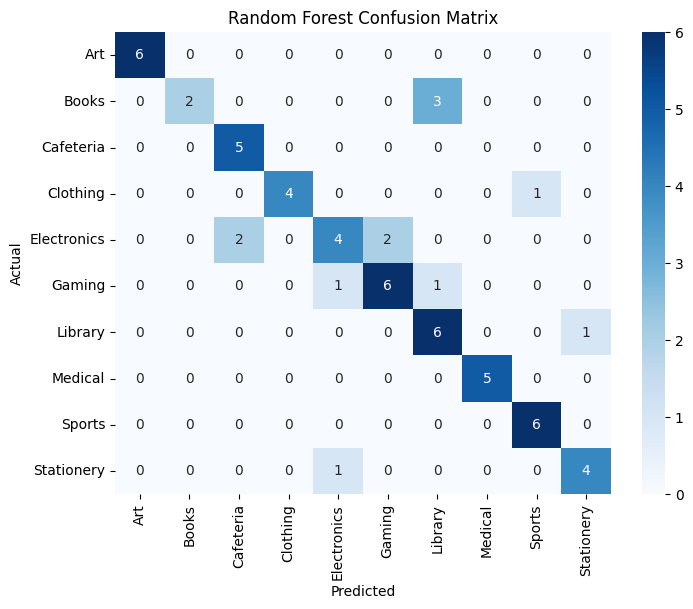

In [17]:
# ============================================================
# Helper Function for Metrics
# ============================================================

all_results = []

def save_metrics(model_name, y_test, preds, train_time):
    result = {
        "Model": model_name,
        "Test Accuracy": accuracy_score(y_test, preds),
        "Macro Precision": precision_score(y_test, preds, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_test, preds, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, preds, average="macro", zero_division=0),
        "Training Time (s)": train_time
    }
    all_results.append(result)
    return result

def print_metrics(title, metrics):
    print(title)
    for k, v in metrics.items():
        if k != "Model":
            print(f"{k}: {v:.4f}")

# ============================================================
# 10. Random Forest
# ============================================================

rf_param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10],
    "max_features": ["sqrt", "log2"]
}

start = time.time()

if cv_folds < 2:
    print("Not enough samples for RF GridSearchCV. Training default Random Forest.")

    rf_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        max_features="sqrt",
        random_state=RANDOM_STATE
    )
    rf_model.fit(X_train, y_train)
    rf_best_params = {
        "n_estimators": 100,
        "max_depth": None,
        "max_features": "sqrt"
    }

else:
    rf_grid = GridSearchCV(
        RandomForestClassifier(random_state=RANDOM_STATE),
        rf_param_grid,
        cv=cv_folds,
        scoring="f1_macro",
        n_jobs=-1
    )
    rf_grid.fit(X_train, y_train)
    rf_model = rf_grid.best_estimator_
    rf_best_params = rf_grid.best_params_

rf_time = time.time() - start
rf_preds = rf_model.predict(X_test)

rf_metrics = save_metrics("Random Forest", y_test, rf_preds, rf_time)

print("# Random Forest")
print("best_params =", rf_best_params)
print_metrics("", rf_metrics)

# Feature Importances
importances = pd.Series(rf_model.feature_importances_, index=feature_names)
top20 = importances.sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 6))
top20.sort_values().plot(kind="barh")
plt.title("Random Forest Top 20 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

# Confusion Matrix
cm = confusion_matrix(y_test, rf_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Bagging Explanation


## 6. Boosting

# AdaBoost
best_params = {'learning_rate': 1.0, 'n_estimators': 200}

Test Accuracy: 0.8000
Macro Precision: 0.8885
Macro Recall: 0.7940
Macro F1: 0.8098
Training Time (s): 7.0647
# Gradient Boosting
best_params = {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 50}

Test Accuracy: 0.8500
Macro Precision: 0.8774
Macro Recall: 0.8557
Macro F1: 0.8563
Training Time (s): 123.1991


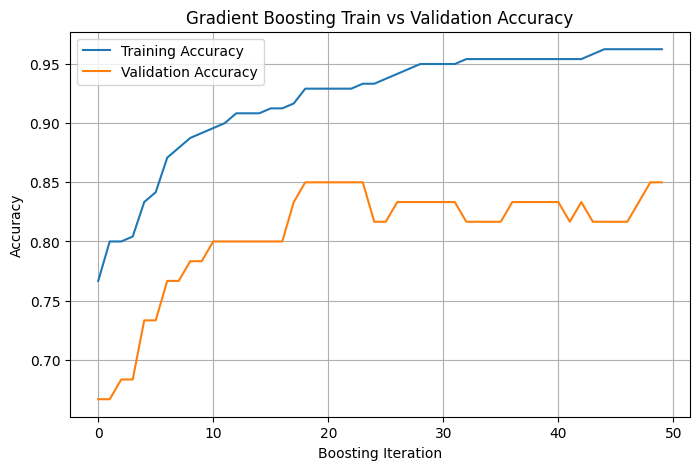

In [18]:
# ============================================================
# 11. AdaBoost
# ============================================================

ada_param_grid = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.5, 1.0]
}

try:
    ada_base = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
        random_state=RANDOM_STATE
    )
except TypeError:
    ada_base = AdaBoostClassifier(
        base_estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
        random_state=RANDOM_STATE
    )

start = time.time()

if cv_folds < 2:
    print("Not enough samples for AdaBoost GridSearchCV. Training default AdaBoost.")

    ada_model = ada_base
    ada_model.fit(X_train, y_train)
    ada_best_params = {
        "n_estimators": ada_model.n_estimators,
        "learning_rate": ada_model.learning_rate
    }

else:
    ada_grid = GridSearchCV(
        ada_base,
        ada_param_grid,
        cv=cv_folds,
        scoring="f1_macro",
        n_jobs=-1
    )
    ada_grid.fit(X_train, y_train)
    ada_model = ada_grid.best_estimator_
    ada_best_params = ada_grid.best_params_

ada_time = time.time() - start
ada_preds = ada_model.predict(X_test)

ada_metrics = save_metrics("AdaBoost", y_test, ada_preds, ada_time)

print("# AdaBoost")
print("best_params =", ada_best_params)
print_metrics("", ada_metrics)

# ============================================================
# 12. Gradient Boosting
# ============================================================

gb_param_grid = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.05, 0.1, 0.2],
    "max_depth": [3, 5]
}

start = time.time()

if cv_folds < 2:
    print("Not enough samples for Gradient Boosting GridSearchCV. Training default Gradient Boosting.")

    gb_model = GradientBoostingClassifier(random_state=RANDOM_STATE)
    gb_model.fit(X_train, y_train)
    gb_best_params = {
        "n_estimators": gb_model.n_estimators,
        "learning_rate": gb_model.learning_rate,
        "max_depth": gb_model.max_depth
    }

else:
    gb_grid = GridSearchCV(
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        gb_param_grid,
        cv=cv_folds,
        scoring="f1_macro",
        n_jobs=-1
    )
    gb_grid.fit(X_train, y_train)
    gb_model = gb_grid.best_estimator_
    gb_best_params = gb_grid.best_params_

gb_time = time.time() - start
gb_preds = gb_model.predict(X_test)

gb_metrics = save_metrics("Gradient Boosting", y_test, gb_preds, gb_time)

print("# Gradient Boosting")
print("best_params =", gb_best_params)
print_metrics("", gb_metrics)

# Train vs validation loss curve
train_scores = []
val_scores = []

for pred_train, pred_test in zip(gb_model.staged_predict(X_train), gb_model.staged_predict(X_test)):
    train_scores.append(accuracy_score(y_train, pred_train))
    val_scores.append(accuracy_score(y_test, pred_test))

plt.figure(figsize=(8, 5))
plt.plot(train_scores, label="Training Accuracy")
plt.plot(val_scores, label="Validation Accuracy")
plt.title("Gradient Boosting Train vs Validation Accuracy")
plt.xlabel("Boosting Iteration")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [19]:
# ============================================================
# 13. XGBoost
# ============================================================

if xgb_available:

    xgb_param_grid = {
        "n_estimators": [50, 100],
        "learning_rate": [0.05, 0.1],
        "max_depth": [3, 6]
    }

    start = time.time()

    if cv_folds < 2:
        print("Not enough samples for XGBoost GridSearchCV. Training default XGBoost.")

        xgb_model = XGBClassifier(
            random_state=RANDOM_STATE,
            eval_metric="mlogloss"
        )
        xgb_model.fit(X_train, y_train)
        xgb_best_params = {
            "n_estimators": xgb_model.n_estimators,
            "learning_rate": xgb_model.learning_rate,
            "max_depth": xgb_model.max_depth
        }

    else:
        xgb_grid = GridSearchCV(
            XGBClassifier(
                random_state=RANDOM_STATE,
                eval_metric="mlogloss"
            ),
            xgb_param_grid,
            cv=cv_folds,
            scoring="f1_macro",
            n_jobs=-1
        )
        xgb_grid.fit(X_train, y_train)
        xgb_model = xgb_grid.best_estimator_
        xgb_best_params = xgb_grid.best_params_

    xgb_time = time.time() - start
    xgb_preds = xgb_model.predict(X_test)

    xgb_metrics = save_metrics("XGBoost", y_test, xgb_preds, xgb_time)

    print("# XGBoost")
    print("best_params =", xgb_best_params)
    print_metrics("", xgb_metrics)

# XGBoost
best_params = {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}

Test Accuracy: 0.8167
Macro Precision: 0.8583
Macro Recall: 0.8157
Macro F1: 0.8022
Training Time (s): 5.6182


## 7. Ensemble vs Single-Classifier Comparison

,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Training Time (s)
7,SVM,0.850000,0.883135,0.860833,0.860439,0.383020
2,Gradient Boosting,0.850000,0.877381,0.855714,0.856312,123.199078
6,Naive Bayes,0.833333,0.858810,0.838810,0.834278,0.001934
5,KNN,0.800000,0.820556,0.815595,0.815898,0.121735
1,AdaBoost,0.800000,0.888462,0.794048,0.809798,7.064703
0,Random Forest,0.800000,0.838810,0.810714,0.804404,29.532574
3,XGBoost,0.816667,0.858254,0.815714,0.802233,5.618225
4,Decision Tree,0.650000,0.697698,0.654881,0.648824,0.004088
8,Rule-Based,0.383333,0.415421,0.388690,0.342361,0.007237


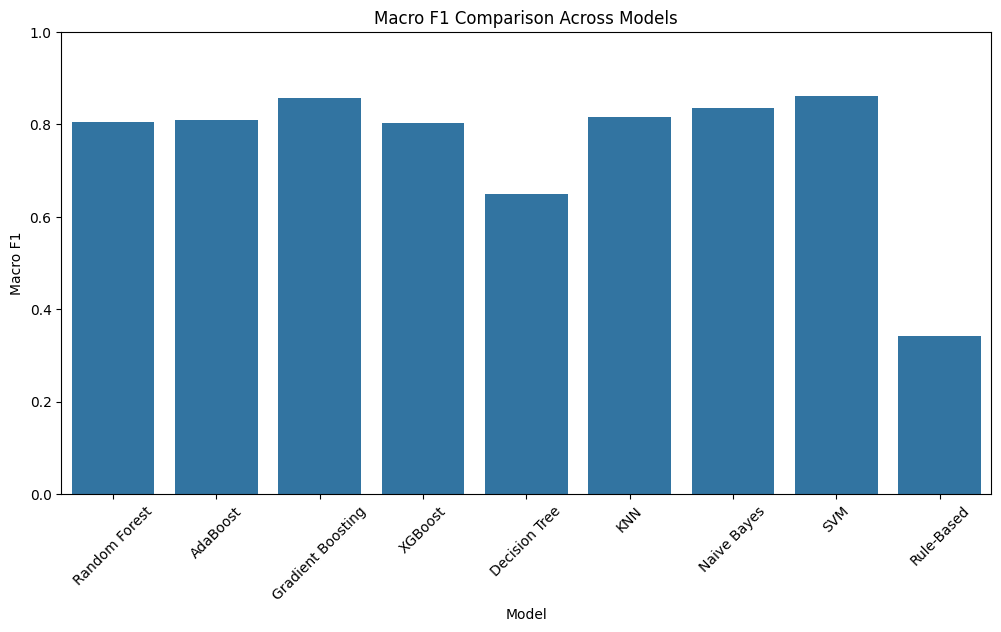

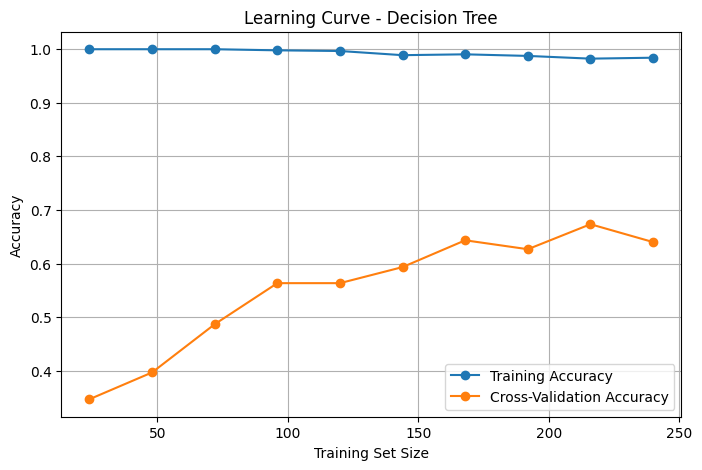

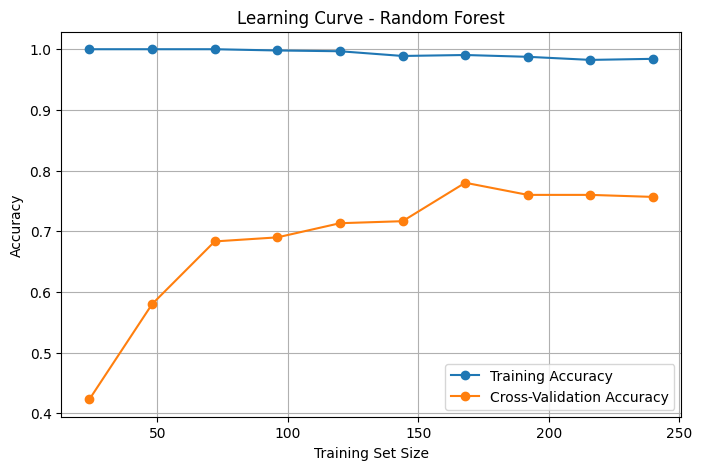

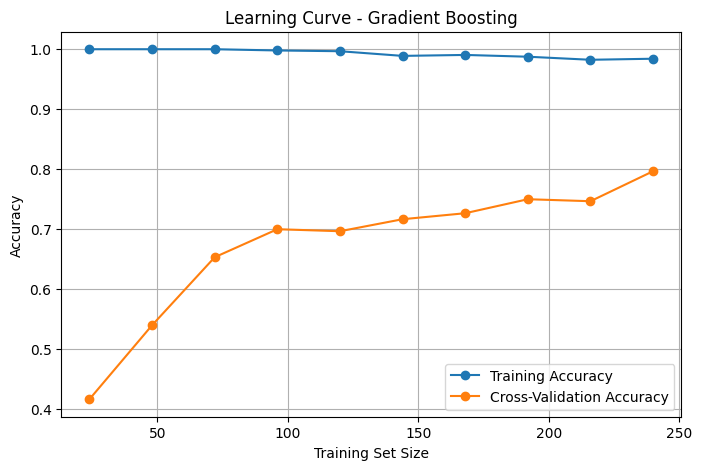

In [20]:
# ============================================================
# 14. HW6 Single Classifiers
# ============================================================

# Decision Tree
start = time.time()
dt_model = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_model.fit(X_train, y_train)
dt_time = time.time() - start
dt_preds = dt_model.predict(X_test)
dt_metrics = save_metrics("Decision Tree", y_test, dt_preds, dt_time)

# KNN
knn_param_grid = {
    "n_neighbors": [3, 5, 7]
}

start = time.time()

if cv_folds < 2:
    knn_model = KNeighborsClassifier(n_neighbors=3)
    knn_model.fit(X_train, y_train)
else:
    knn_grid = GridSearchCV(
        KNeighborsClassifier(),
        knn_param_grid,
        cv=cv_folds,
        scoring="f1_macro",
        n_jobs=-1
    )
    knn_grid.fit(X_train, y_train)
    knn_model = knn_grid.best_estimator_

knn_time = time.time() - start
knn_preds = knn_model.predict(X_test)
knn_metrics = save_metrics("KNN", y_test, knn_preds, knn_time)

# Naive Bayes
start = time.time()
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
nb_time = time.time() - start
nb_preds = nb_model.predict(X_test)
nb_metrics = save_metrics("Naive Bayes", y_test, nb_preds, nb_time)

# SVM
svm_param_grid = {
    "kernel": ["linear", "rbf"],
    "C": [0.1, 1, 10]
}

start = time.time()

if cv_folds < 2:
    svm_model = SVC(kernel="linear", random_state=RANDOM_STATE)
    svm_model.fit(X_train, y_train)
else:
    svm_grid = GridSearchCV(
        SVC(random_state=RANDOM_STATE),
        svm_param_grid,
        cv=cv_folds,
        scoring="f1_macro",
        n_jobs=-1
    )
    svm_grid.fit(X_train, y_train)
    svm_model = svm_grid.best_estimator_

svm_time = time.time() - start
svm_preds = svm_model.predict(X_test)
svm_metrics = save_metrics("SVM", y_test, svm_preds, svm_time)

# Rule-Based Method
start = time.time()

def rule_based_predict(row):
    row = pd.Series(row, index=feature_names)

    if row.get("Mouse", 0) > 0 or row.get("Keyboard", 0) > 0 or row.get("Charger", 0) > 0:
        return "Electronics"
    elif row.get("Coffee", 0) > 0 or row.get("Muffin", 0) > 0 or row.get("Tea", 0) > 0:
        return "Cafeteria"
    elif row.get("Bookmark", 0) > 0 or row.get("Textbook", 0) > 0:
        return "Books"
    elif row.get("Pen", 0) > 0 or row.get("Notebook", 0) > 0 or row.get("Stapler", 0) > 0:
        return "Stationery"
    elif row.get("Highlighter", 0) > 0 or row.get("Library_Card", 0) > 0:
        return "Library"
    elif row.get("Controller", 0) > 0 or row.get("Headphones", 0) > 0 or row.get("Mousepad", 0) > 0:
        return "Gaming"
    else:
        return le.classes_[0]

X_test_original_scale = scaler.inverse_transform(X_test)
rule_preds_text = [rule_based_predict(row) for row in X_test_original_scale]

# Handle unseen rule labels safely
rule_preds_text = [
    pred if pred in le.classes_ else le.classes_[0]
    for pred in rule_preds_text
]

rule_preds = le.transform(rule_preds_text)
rule_time = time.time() - start

rule_metrics = save_metrics("Rule-Based", y_test, rule_preds, rule_time)

# ============================================================
# 15. Unified Comparison Table
# ============================================================

comparison_df = pd.DataFrame(all_results)

comparison_df = comparison_df[
    [
        "Model",
        "Test Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Training Time (s)"
    ]
]

display(comparison_df.sort_values(by="Macro F1", ascending=False))

plt.figure(figsize=(12, 6))
sns.barplot(data=comparison_df, x="Model", y="Macro F1")
plt.title("Macro F1 Comparison Across Models")
plt.xlabel("Model")
plt.ylabel("Macro F1")
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.show()

# ============================================================
# 16. Learning Curves: Bias-Variance Analysis
# ============================================================

def plot_learning_curve_model(model, model_name):
    train_sizes, train_scores, cv_scores = learning_curve(
        model,
        X_scaled,
        y_encoded,
        train_sizes=np.linspace(0.1, 1.0, 10),
        cv=max(2, min(5, pd.Series(y_encoded).value_counts().min())),
        scoring="accuracy",
        n_jobs=-1
    )

    train_mean = np.mean(train_scores, axis=1)
    cv_mean = np.mean(cv_scores, axis=1)

    plt.figure(figsize=(8, 5))
    plt.plot(train_sizes, train_mean, marker="o", label="Training Accuracy")
    plt.plot(train_sizes, cv_mean, marker="o", label="Cross-Validation Accuracy")
    plt.title(f"Learning Curve - {model_name}")
    plt.xlabel("Training Set Size")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_learning_curve_model(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Decision Tree"
)

plot_learning_curve_model(
    RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "Random Forest"
)

plot_learning_curve_model(
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting"
)


### Ensemble vs Single-Classifier Analysis

Single classifiers are usually faster and easier to interpret, but they can be less stable when the dataset has many sparse item features. Random Forest improves stability by averaging many decision trees, so it usually reduces overfitting compared to a single tree. Boosting methods such as AdaBoost, Gradient Boosting, and XGBoost focus on correcting previous mistakes, so they can achieve strong predictive performance but may take more training time. The best model should be selected based on Macro F1 as well as training time, because a slightly more accurate model may not always be worth the extra computational cost.

## 8. Bias–Variance Analysis

### Bias–Variance Interpretation

A Decision Tree often shows high variance because it can fit the training data very closely, especially when the tree is deep. Random Forest reduces this variance by training many trees on different bootstrap samples and averaging their predictions. Gradient Boosting mainly helps reduce bias by building trees sequentially, where each new tree tries to correct the errors of the previous trees. If the training accuracy is high but cross-validation accuracy is much lower, the model is overfitting; if both are low, the model has high bias. The best model is the one where the training and validation curves are both high and close to each other.

In [21]:

# ============================================================
# 17. Final Classification Reports
# ============================================================

print("Random Forest Classification Report")
print(classification_report(y_test, rf_preds, target_names=le.classes_, zero_division=0))

print("AdaBoost Classification Report")
print(classification_report(y_test, ada_preds, target_names=le.classes_, zero_division=0))

print("Gradient Boosting Classification Report")
print(classification_report(y_test, gb_preds, target_names=le.classes_, zero_division=0))

if xgb_available:
    print("XGBoost Classification Report")
    print(classification_report(y_test, xgb_preds, target_names=le.classes_, zero_division=0))

Random Forest Classification Report
              precision    recall  f1-score   support

         Art       1.00      1.00      1.00         6
       Books       1.00      0.40      0.57         5
   Cafeteria       0.71      1.00      0.83         5
    Clothing       1.00      0.80      0.89         5
 Electronics       0.67      0.50      0.57         8
      Gaming       0.75      0.75      0.75         8
     Library       0.60      0.86      0.71         7
     Medical       1.00      1.00      1.00         5
      Sports       0.86      1.00      0.92         6
  Stationery       0.80      0.80      0.80         5

    accuracy                           0.80        60
   macro avg       0.84      0.81      0.80        60
weighted avg       0.82      0.80      0.79        60

AdaBoost Classification Report
              precision    recall  f1-score   support

         Art       1.00      0.50      0.67         6
       Books       1.00      0.60      0.75         5
   Cafeteri